# Computation of Effective area

## Summary
- Load selected gamma rays and all gamma rays from MC
- Bins : 20 in Energy from 1 to 100 GeV, 10 in theta from 0 to 60° (Duan)
- Raffiner les bins par endroit? 

In [1]:
import ROOT, glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

In [2]:
def browse_files(filenames):
    """
    Browse through the list of filenames and return a sorted list of files.
    """
    if isinstance(filenames, str):
        files = sorted(glob.glob(filenames))
    elif isinstance(filenames, list):
        files = []
        for filename in filenames:
            files += sorted(glob.glob(filename))
    else:
        raise ValueError("Input should be a string or a list of strings.")
    
    return files


## Load MC data

In [3]:
dirDir= "/home/users/l/lebrun/"
dataDir = "/dpnc/beegfs/dampe/tryf/MC_Skimmed/MC_gamma/"
figPath_ = dirDir + "figures/"
resultPath = dirDir + "results/"
dataPath1 = dirDir + "data/"
dataPath2 = "/dpnc/beegfs/dampe/tryf/ForKimberly/"
# filename1 = dataDir + "DmlNtup_gamma_part*_TQ_FullSel.root"
# filename2 = dataDir + "DmlNtup_gamma_100GeV_1TeV_part*_TQ_FullSel.root"
# filename3 = dataDir + "DmlNtup_gamma_1TeV_10TeV_part*_MPhotonSelProj_TQ_FullSel.root"

# filenames_LET = [filename1, filename2]
# filenames_HET = [filename1, filename2, filename3]

# Find all matching ROOT files : from 1 GeV to 100 GeV
# files = list()
# for filename in filenames_HET:
#     files += sorted(glob.glob(filename))
exponent = 0

figPath = figPath_+f"effArea/exp{exponent:.1f}/"
# file = dataPath + f"MC_exp{exponent:.1f}.root"

dataPath_scaled = dirDir + "data/" + "scaled" + "_cos_theta_bins/"
dataPath_scaled += f"exp{exponent:.1f}/"

files_scaled = browse_files(dataPath_scaled + "*.root")

dataPath_filtered = dataPath2 + "filtered" + "_cos_theta_bins/"
dataPath_filtered += f"exp{exponent:.1f}/"
print(f"dataPath_filtered: {dataPath_filtered}")

files_filtered = browse_files(dataPath_filtered + "*.root")

# Pass the list of files to RDataFrame
# DmlNtup
print(f"Loading files: {files_scaled}")
rdf = ROOT.RDataFrame("MC", files_scaled)

print(f"Loading files: {files_filtered}")
rdf_filtered = ROOT.RDataFrame("MC", files_filtered)
rdf_filtered = rdf_filtered.Filter("tt_isHET == 1")

# # Apply cut on FoV
# rdf = rdf.Filter("theta_True < 60")


dataPath_filtered: /dpnc/beegfs/dampe/tryf/ForKimberly/filtered_cos_theta_bins/exp0.0/
Loading files: ['/home/users/l/lebrun/data/scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_0.root', '/home/users/l/lebrun/data/scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_1.root', '/home/users/l/lebrun/data/scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_10.root', '/home/users/l/lebrun/data/scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_11.root', '/home/users/l/lebrun/data/scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_12.root', '/home/users/l/lebrun/data/scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_13.root', '/home/users/l/lebrun/data/scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_14.root', '/home/users/l/lebrun/data/scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_15.root', '/home/users/l/lebrun/data/scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_16.root', '/home/users/l/lebrun/data/scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_17.root', '/home/users/l/lebrun/data/scaled_cos_t

In [4]:
# Extract only desired columns

df = rdf.AsNumpy(["E_true", "weight", "theta_True"])
df = pd.DataFrame(df)
print("Number of entries in original : ", len(df))

Number of entries in original :  39048764


## Necessary transformations

In [5]:
# Print min max of E_true
print(f"Minimum E_true: {df['E_true'].min()} GeV")
print(f"Maximum E_true: {df['E_true'].max()} GeV")

df['theta_True_deg']= df['theta_True']
print(f"Minimum theta_True: {df['theta_True_deg'].min()} degrees")
print(f"Maximum theta_True: {df['theta_True_deg'].max()} degrees")
df['theta_True'] = np.deg2rad(df['theta_True'])
df['cosTheta'] = np.cos(df['theta_True'])

Minimum E_true: 1.0000006282052336 GeV


Maximum E_true: 9999.96505258949 GeV
Minimum theta_True: 0.015008423657870201 degrees
Maximum theta_True: 89.99999169247724 degrees


## TODO : load filtered data

In [6]:
# Load filtered data here
#dfHET = pd.read_csv(dataPath + f"MC_het_exp{exponent:.1f}_filtered_energy.csv")
dfHET = rdf_filtered.AsNumpy(["weight", "theta_True", "tt_isHET", "tt_ekin"])
dfHET = pd.DataFrame(dfHET)

# Print number of events
# Print number of event in df
print(f"Number of events in original data: {len(df)}")
print(f"Number of events in filtered data: {len(dfHET)}")

# Filter the DataFrame to keep only HET events
dfHET = dfHET[dfHET['tt_isHET'] == 1]
# Print number of HET events
print(f"Number of HET events: {len(dfHET)}")
# Add energy column in GeV
dfHET['E_true'] = dfHET['tt_ekin'] * 1e-3 # Convert tt_ekin from MeV to GeV
# Print min max of E_true
print(f"Minimum E_true: {dfHET['E_true'].min()} GeV")
print(f"Maximum E_true: {dfHET['E_true'].max()} GeV")

dfHET = dfHET[dfHET['E_true'] <= 1e4]
print(f"Number of HET events with E_true <= 10 TeV: {len(dfHET)}")

dfHET['theta_True_deg']= dfHET['theta_True']
dfHET['theta_True'] = np.deg2rad(dfHET['theta_True'])
dfHET['cosTheta'] = np.cos(dfHET['theta_True'])

print(f"Minimum theta_True: {dfHET['theta_True_deg'].min()} degrees")
print(f"Maximum theta_True: {dfHET['theta_True_deg'].max()} degrees")

# dfHET = dfHET[dfHET['theta_True_deg'] < 60]
# print(f"Number of HET events with theta_True < 60: {len(dfHET)}")

Number of events in original data: 39048764
Number of events in filtered data: 2500072
Number of HET events: 2500072
Minimum E_true: 1.220147597224916 GeV
Maximum E_true: 9998.562154091216 GeV
Number of HET events with E_true <= 10 TeV: 2500072
Minimum theta_True: 0.02062272442729397 degrees
Maximum theta_True: 89.97767053951249 degrees


## Create bins

In [7]:
Emin = 1
Emax_HET = 1e4
n_E_bins_HET = 40

cos_theta_min = 0.5
cos_theta_max = 1
n_theta_bins = 10

E_bins_edge_HET = np.logspace(np.log10(Emin), np.log10(Emax_HET), n_E_bins_HET + 1)
E_bins_center_HET = np.sqrt(E_bins_edge_HET[:-1] * E_bins_edge_HET[1:])

theta_bins_edge = np.linspace(cos_theta_min, cos_theta_max, n_theta_bins + 1)
theta_bins_center = (theta_bins_edge[:-1] + theta_bins_edge[1:])/2

### Check Spectra

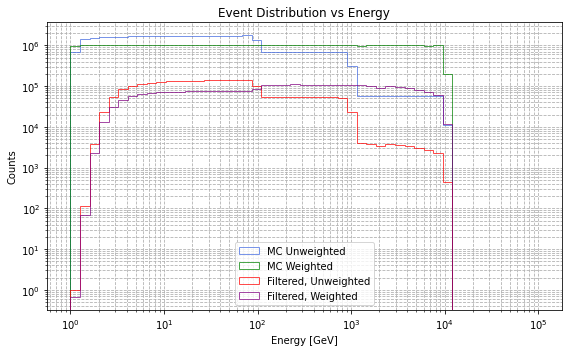

In [8]:
nbins=50

plt.figure(figsize=(8, 5))
plt.hist(df['E_true'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='royalblue', histtype='step', label='MC Unweighted', alpha=0.7)
plt.hist(df['E_true'], weights=df['weight'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='green', histtype='step', label='MC Weighted', alpha=0.7)
plt.hist(dfHET['E_true'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='red', histtype='step', label='Filtered, Unweighted', alpha=0.7)
plt.hist(dfHET['E_true'], weights=dfHET['weight'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='purple', histtype='step', label='Filtered, Weighted', alpha=0.7)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Energy [GeV]")
plt.ylabel("Counts")
plt.title("Event Distribution vs Energy")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.savefig(figPath + f"energy_spectrum_comparison_exp{exponent:.1f}.png", dpi=400)
plt.show()

In [9]:

# Create histograms
hist_all = rdf.Histo1D(
    ("hist_all", "E_true spectrum;E_true [GeV];Counts", n_E_bins_HET, E_bins_edge_HET),
    "E_true"
)

hist_filtered = rdf_filtered.Histo1D(
    ("hist_filtered", "Filtered E_true spectrum;E_true [GeV];Counts", n_E_bins_HET, E_bins_edge_HET),
    "E_true"
)

# Draw the two spectra on the same canvas
c1 = ROOT.TCanvas("c1", "Spectra", 800, 600)
c1.SetLogx()
c1.SetLogy()

hist_all.SetLineColor(ROOT.kBlue)
hist_all.SetLineWidth(2)
hist_filtered.SetLineColor(ROOT.kRed)
hist_filtered.SetLineWidth(2)

hist_all.Draw("HIST")
hist_filtered.Draw("HIST SAME")

# max_y= max((hist_all.GetMaximum(), hist_filtered.GetMaximum())) * 1.2
# min_y = min((hist_all.GetMinimum(1), hist_filtered.GetMinimum(1)))
# min_y = max(min_y, 1e-3)

# hist_all.SetMaximum(max_y)
# hist_all.SetMinimum(min_y)

# hist_filtered.SetMaximum(max_y)
# hist_filtered.SetMinimum(min_y)

legend = ROOT.TLegend(0.65, 0.75, 0.88, 0.88)
legend.AddEntry(hist_all.GetPtr(), "All events", "l")
legend.AddEntry(hist_filtered.GetPtr(), "Filtered events", "l")
legend.Draw()

c1.Draw()

# Create ratio histogram
hist_ratio = hist_filtered.Clone("hist_ratio")
hist_ratio.SetTitle("Filtered / All;E_true [GeV];Ratio")
hist_ratio.Divide(hist_all.GetPtr())  # GetPtr() ensures the C++ object is used

# Draw the ratio
c2 = ROOT.TCanvas("c2", "Ratio", 800, 600)
c2.SetLogx()
hist_ratio.SetLineColor(ROOT.kGreen + 2)
hist_ratio.SetLineWidth(2)
hist_ratio.Draw("HIST")
c2.Draw()

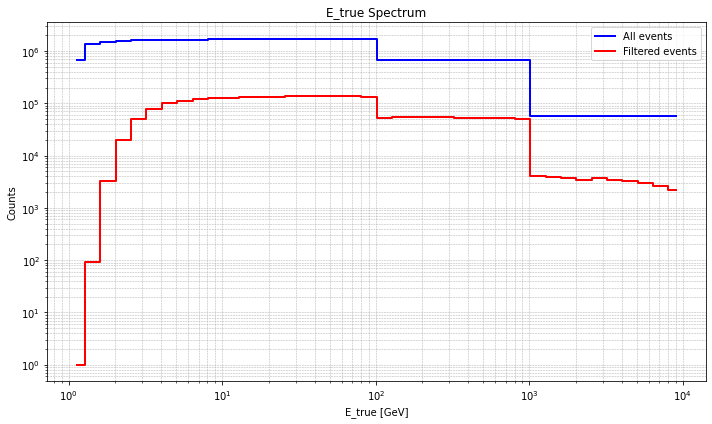

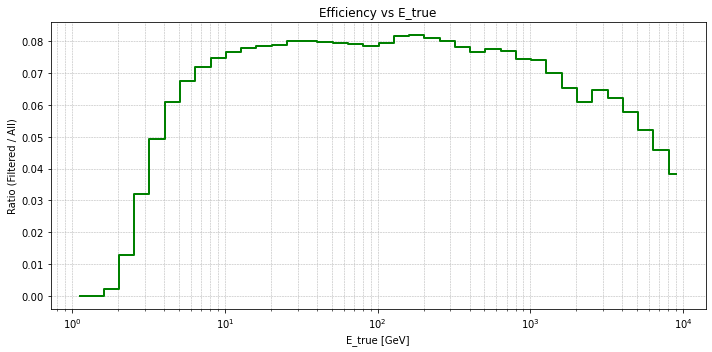

In [10]:
# Step 1: Create histograms
hist_all_counts, bin_edges = np.histogram(df["E_true"], bins=E_bins_edge_HET)
hist_filtered_counts, _ = np.histogram(dfHET["E_true"], bins=E_bins_edge_HET)

# Step 2: Plot histograms (like ROOT canvas c1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

plt.figure(figsize=(10, 6))
plt.plot(bin_centers, hist_all_counts, drawstyle='steps-mid', label="All events", color='blue', linewidth=2)
plt.plot(bin_centers, hist_filtered_counts, drawstyle='steps-mid', label="Filtered events", color='red', linewidth=2)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("E_true [GeV]")
plt.ylabel("Counts")
plt.title("E_true Spectrum")
plt.legend(loc="upper right")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.tight_layout()
plt.show()

# Avoid division by zero
with np.errstate(divide='ignore', invalid='ignore'):
    ratio = np.divide(hist_filtered_counts, hist_all_counts)
    ratio[hist_all_counts == 0] = np.nan  # or 0, depending on what you prefer

plt.figure(figsize=(10, 5))
plt.plot(bin_centers, ratio, drawstyle='steps-mid', color='green', linewidth=2)
plt.xscale("log")
plt.xlabel("E_true [GeV]")
plt.ylabel("Ratio (Filtered / All)")
plt.title("Efficiency vs E_true")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.tight_layout()
plt.show()


### Bin the MC data

In [11]:
# Assign bin indices
df['E_bin_HET'] = pd.cut(df['E_true'], bins=E_bins_edge_HET, labels=False, include_lowest=True)
df['cos_theta_bin'] = pd.cut(df['cosTheta'], bins=theta_bins_edge, labels=False, include_lowest=True)

# Drop rows that fall outside the bins (e.g., NaN bin index)
df = df.dropna(subset=['E_bin_HET', 'E_bin_HET' , 'cos_theta_bin']).copy() # Copy to avoid SettingWithCopyWarning

# Make sure bin indices are integers
df['E_bin_HET'] = df['E_bin_HET'].astype(int)
df['cos_theta_bin'] = df['cos_theta_bin'].astype(int)

### Bin the HET data

In [12]:
dfHET['E_bin_HET'] = pd.cut(dfHET['E_true'], bins=E_bins_edge_HET, labels=False, include_lowest=True)
dfHET['cos_theta_bin'] = pd.cut(dfHET['cosTheta'], bins=theta_bins_edge, labels=False, include_lowest=True)
dfHET = dfHET.dropna(subset=['E_bin_HET', 'cos_theta_bin']).copy() # Copy to avoid SettingWithCopyWarning
dfHET['E_bin_HET'] = dfHET['E_bin_HET'].astype(int)
dfHET['cos_theta_bin'] = dfHET['cos_theta_bin'].astype(int)

## Bin df_results

In [13]:
# Group original events (denominator)
total_counts = (
    df.groupby(['E_bin_HET', 'cos_theta_bin'])
    .size()
    .rename('total').sort_index()
)

# Group accepted events (numerator)
accepted_counts = (
    dfHET.groupby(['E_bin_HET', 'cos_theta_bin'])
    .size()
    .rename('accepted').sort_index()
)

# Group original events with weights (denominator)
total_weights = (
    df.groupby(['E_bin_HET', 'cos_theta_bin'])['weight']
    .sum()
    .rename('total_weight').sort_index()
)
#total_weigths.sort_values(['E_bin_HET', 'cos_theta_bin'], ascending=[True, True], inplace=True)

# Group accepted events with weights (numerator)
accepted_weights = (
    dfHET.groupby(['E_bin_HET', 'cos_theta_bin'])['weight']
    .sum()
    .rename('accepted_weight').sort_index()
)
#accepted_weights.sort_values(['E_bin_HET', 'cos_theta_bin'], ascending=[True, True], inplace=True)
#print(total_counts)
#print(accepted_counts)

# Join and compute acceptance and effarea
r = 1.38*1e2 # cm
phi_norm = 2*np.pi # used to average over azimuthal angle
df_results_geom = 37.59 * 1e4 # cm^2 sr

#eff_area_geom = (np.pi)*(r**2)/ phi_norm # cm^2
cross_section = 6 # m^2
eff_area_geom = 6*1e4/ phi_norm # cm^2
df_results = pd.concat([accepted_counts, total_counts, accepted_weights, total_weights], axis=1).fillna(0)
print("total counts : ", total_counts.head())
print("accepted counts : ", accepted_counts.head())
print("df_results : ", df_results.head())


total counts :  E_bin_HET  cos_theta_bin
0          0                28950
           1                35023
           2                40542
           3                46132
           4                52506
Name: total, dtype: int64
accepted counts :  E_bin_HET  cos_theta_bin
0          8                1
1          2                1
           3                4
           4                2
           5                3
Name: accepted, dtype: int64
df_results :                           accepted   total  accepted_weight  total_weight
E_bin_HET cos_theta_bin                                                 
0         8                   1.0   75856         0.673234  94416.397532
1         2                   1.0   86703         0.634126  60252.425992
          3                   4.0   98786         2.589108  66944.844679
          4                   2.0  109965         1.236734  73051.458042
          5                   3.0  120702         1.834701  79263.648628


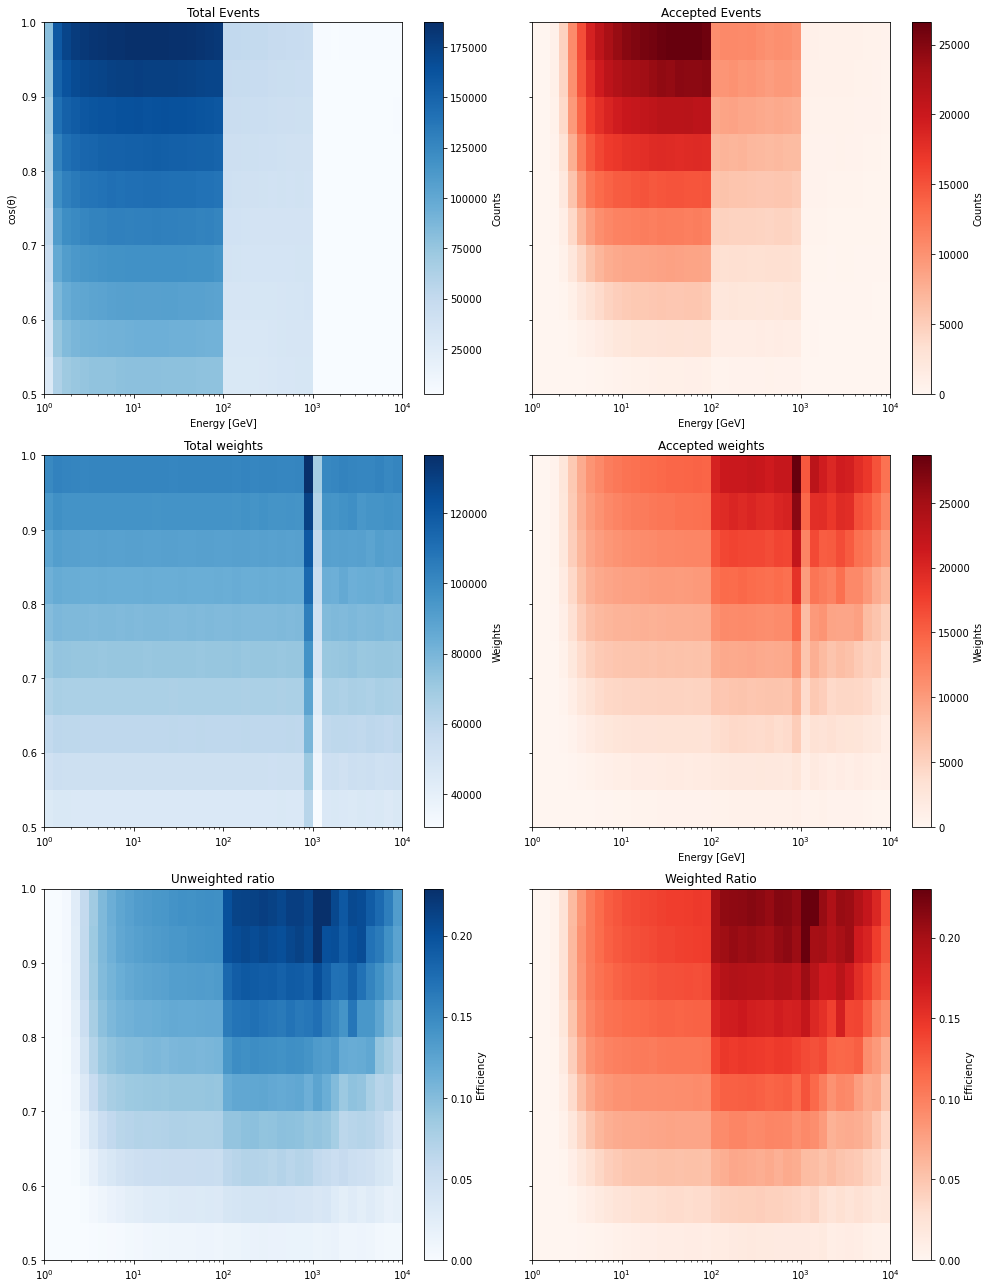

In [14]:
fig, axs = plt.subplots(3, 2, figsize=(14, 18), sharey=True)
df_results = df_results.reset_index()
df_results = df_results.sort_values(['E_bin_HET', 'cos_theta_bin'])
# Prepare 2D arrays for total and accepted counts from df_results
total_grid = df_results.pivot(index='cos_theta_bin', columns='E_bin_HET', values='total').values
accepted_grid = df_results.pivot(index='cos_theta_bin', columns='E_bin_HET', values='accepted').values
total_grid_w = df_results.pivot(index='cos_theta_bin', columns='E_bin_HET', values='total_weight').values
accepted_grid_w = df_results.pivot(index='cos_theta_bin', columns='E_bin_HET', values='accepted_weight').values


# Plot total counts
c1 = axs[0][0].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, total_grid,
    shading='auto', cmap='Blues'
)
axs[0][0].set_xscale('log')
axs[0][0].set_xlabel("Energy [GeV]")
axs[0][0].set_ylabel("cos(θ)")
axs[0][0].set_title("Total Events")
fig.colorbar(c1, ax=axs[0][0], label='Counts')

# Plot accepted counts
c2 = axs[0][1].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, accepted_grid,
    shading='auto', cmap='Reds'
)
axs[0][1].set_xscale('log')
axs[0][1].set_xlabel("Energy [GeV]")
axs[0][1].set_title("Accepted Events")
fig.colorbar(c2, ax=axs[0][1], label='Counts')

# Plot accepted counts
c3 = axs[1][0].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, total_grid_w,
    shading='auto', cmap='Blues'
)
axs[1][0].set_xscale('log')
axs[1][0].set_title("Total weights")
fig.colorbar(c3, ax=axs[1][0], label='Weights')

# Plot accepted counts
c4 = axs[1][1].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, accepted_grid_w,
    shading='auto', cmap='Reds'
)
axs[1][1].set_xscale('log')
axs[1][1].set_xlabel("Energy [GeV]")
axs[1][1].set_title("Accepted weights")
fig.colorbar(c4, ax=axs[1][1], label='Weights')


# Plot ratio unweighted
c4 = axs[2][0].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, np.divide(accepted_grid,total_grid),
    shading='auto', cmap='Blues'
)
axs[2][0].set_xscale('log')
axs[2][0].set_title("Unweighted ratio")
fig.colorbar(c4, ax=axs[2][0], label='Efficiency')

# Plot accepted counts
c5 = axs[2][1].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, np.divide(accepted_grid_w,total_grid_w),
    shading='auto', cmap='Reds'
)
axs[2][1].set_xscale('log')
axs[2][1].set_title("Weighted Ratio")
fig.colorbar(c5, ax=axs[2][1], label='Efficiency')


plt.tight_layout()
fig.savefig(figPath + f"total_vs_accepted_counts_exp{exponent:.1f}.png")
plt.show()



In [15]:

df_results['acceptance'] = df_results['accepted'] * df_results_geom / df_results['total']
df_results['effArea'] = df_results['accepted'] * eff_area_geom / df_results['total']
df_results['acceptance_w'] = df_results['accepted_weight'] * df_results_geom / df_results['total_weight']
df_results['effArea_w'] = df_results['accepted_weight'] * eff_area_geom / df_results['total_weight']
# Optional: reset index if you want a flat DataFrame
df_results = df_results.reset_index()
df_results = df_results.sort_values(['E_bin_HET', 'cos_theta_bin'])
print(df_results.head())
# If you want to save:
df_results.to_csv(resultPath + "effArea_df_HET.csv", index=False)

np.savez(
    resultPath + "effArea_bins_info_HET.npz",
    E_bins_edge_HET=E_bins_edge_HET,
    E_bins_center_HET=E_bins_center_HET,
    theta_bins_edge=theta_bins_edge,
    theta_bins_center=theta_bins_center
)


   index  E_bin_HET  cos_theta_bin  accepted  total  accepted_weight  \
0    388          0              0       0.0  28950              0.0   
1    389          0              1       0.0  35023              0.0   
2    390          0              2       0.0  40542              0.0   
3    391          0              3       0.0  46132              0.0   
4    392          0              4       0.0  52506              0.0   

   total_weight  acceptance  effArea  acceptance_w  effArea_w  
0  44926.815716         0.0      0.0           0.0        0.0  
1  51760.992587         0.0      0.0           0.0        0.0  
2  58057.773435         0.0      0.0           0.0        0.0  
3  64349.974015         0.0      0.0           0.0        0.0  
4  70543.249443         0.0      0.0           0.0        0.0  


In [16]:
# Compute the relative difference between the weighted and unweighted effective area
df_results['effArea_rel_diff'] = np.abs(df_results['effArea_w'] - df_results['effArea']) / df_results['effArea']
# Print the DataFrame with relative differences
print(df_results[['E_bin_HET', 'cos_theta_bin', 'effArea', 'effArea_w', 'effArea_rel_diff']])


     E_bin_HET  cos_theta_bin      effArea    effArea_w  effArea_rel_diff
0            0              0     0.000000     0.000000               NaN
1            0              1     0.000000     0.000000               NaN
2            0              2     0.000000     0.000000               NaN
3            0              3     0.000000     0.000000               NaN
4            0              4     0.000000     0.000000               NaN
..         ...            ...          ...          ...               ...
395         39              5   643.295480   643.199913          0.000149
396         39              6   870.007431   870.304730          0.000342
397         39              7  1067.759964  1067.385819          0.000350
398         39              8  1195.871195  1194.693834          0.000985
399         39              9  1269.192843  1268.985747          0.000163

[400 rows x 5 columns]


In [17]:

# Print min, max and average difference in %
min_diff = df_results['effArea_rel_diff'].min() * 100
max_diff = df_results['effArea_rel_diff'].max() * 100
avg_diff = df_results['effArea_rel_diff'].mean() * 100
median_diff = df_results['effArea_rel_diff'].median() * 100

print(f"Minimum relative difference in effective area: {min_diff:.2f}%")
print(f"Maximum relative difference in effective area: {max_diff:.2f}%")
print(f"Average relative difference in effective area: {avg_diff:.2f}%")
print(f"Median relative difference in effective area: {median_diff:.2f}%")

Minimum relative difference in effective area: 0.00%
Maximum relative difference in effective area: 45.91%
Average relative difference in effective area: 0.40%
Median relative difference in effective area: 0.01%


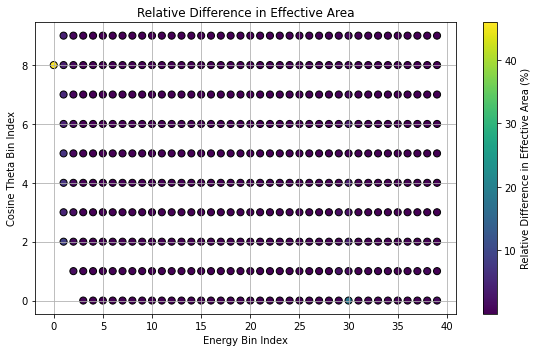

In [18]:
# Plot relative difference in effective area
plt.figure(figsize=(8, 5))  
plt.scatter(df_results['E_bin_HET'], df_results['cos_theta_bin'], 
            c=df_results['effArea_rel_diff'] * 100, cmap='viridis', s=50, edgecolor='k')
plt.colorbar(label='Relative Difference in Effective Area (%)')
plt.xlabel('Energy Bin Index')
plt.ylabel('Cosine Theta Bin Index')
plt.title('Relative Difference in Effective Area')
plt.grid(True)
plt.tight_layout()
plt.savefig(figPath + f"effArea_rel_diff_exp{exponent:.1f}.png", dpi=400)
plt.show()

In [19]:
# Create 2D array of df_results values: shape (n_theta_bins, n_E_bins)
df_results_grid = df_results.pivot(index='cos_theta_bin', columns='E_bin_HET', values='effArea').values
df_results_grid_w = df_results.pivot(index='cos_theta_bin', columns='E_bin_HET', values='effArea_w').values

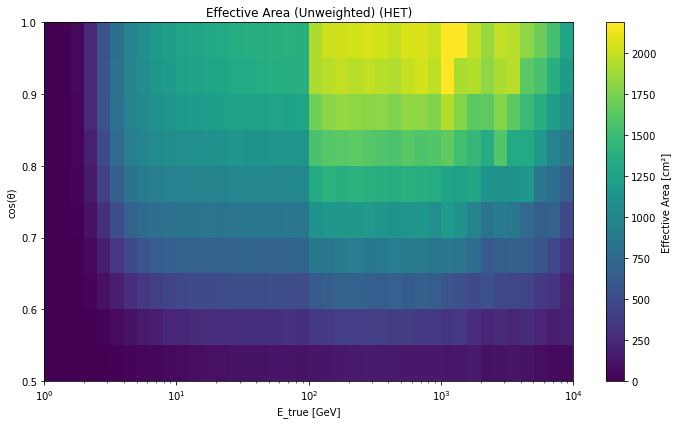

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
mesh = ax.pcolormesh(
    E_bins_edge_HET, theta_bins_edge, df_results_grid,
    shading='auto', cmap='viridis'
)

# Log scale for E axis if needed
ax.set_xscale('log')

# Labels and title
ax.set_xlabel("E_true [GeV]")
ax.set_ylabel("cos(θ)")
ax.set_title("Effective Area (Unweighted) (HET)")
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("Effective Area [cm²]")

plt.tight_layout()
plt.show()

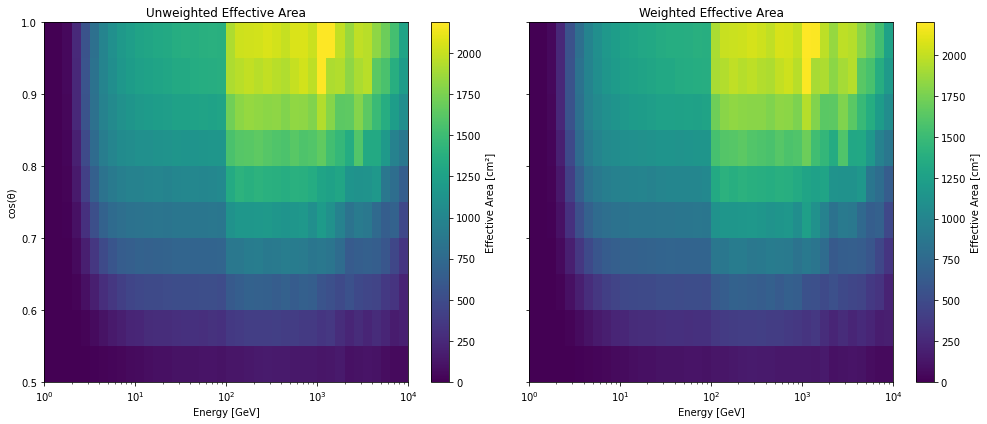

In [21]:
# Prepare color scale (optional: shared scale)
vmin = np.nanmin([df_results_grid, df_results_grid_w])
vmax = np.nanmax([df_results_grid, df_results_grid_w])

fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Unweighted
c1 = axs[0].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, df_results_grid,
    shading='auto', cmap='viridis'#, vmin=vmin, vmax=vmax
)
axs[0].set_xscale('log')
axs[0].set_xlabel("Energy [GeV]")
axs[0].set_ylabel("cos(θ)")
axs[0].set_title("Unweighted Effective Area")
fig.colorbar(c1, ax=axs[0], label='Effective Area [cm²]')

# Weighted
c2 = axs[1].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, df_results_grid_w,
    shading='auto', cmap='viridis'#, vmin=vmin, vmax=vmax
)
axs[1].set_xscale('log')
axs[1].set_xlabel("Energy [GeV]")
axs[1].set_title("Weighted Effective Area")
fig.colorbar(c2, ax=axs[1], label='Effective Area [cm²]')

plt.tight_layout()
fig.savefig(figPath + f"resolutionMap_HET_unweighted_vs_weighted_exp{exponent:.1f}.png")
plt.show()

## Integrate over theta

/tmp/ipykernel_3584857/3990312705.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: {


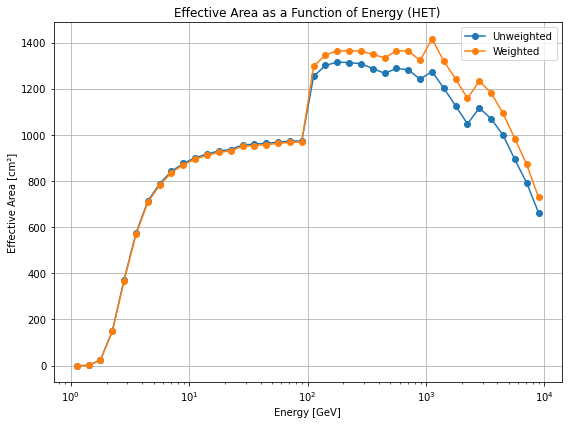

In [22]:
# Redo the same but sum over theta bins to get the effective area as a function of energy only
deltaCosTheta = np.mean(theta_bins_edge[1:] - theta_bins_edge[:-1])

df_results_energy = (
    df_results.groupby('E_bin_HET')
    .apply(lambda x: {
        'effArea': x['accepted'].sum() * eff_area_geom/ (x['total'].sum() ),
        'effArea_w': x['accepted_weight'].sum() * eff_area_geom  / (x['total_weight'].sum())
    })
    .apply(pd.Series)
    .reset_index()
)

# Convert bin indices back to centers
df_results_energy['E_bin_HET'] = E_bins_center_HET[df_results_energy['E_bin_HET']]
# Plot the effective area as a function of energy
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(df_results_energy['E_bin_HET'], df_results_energy['effArea'], label='Unweighted', marker='o')
ax.plot(df_results_energy['E_bin_HET'], df_results_energy['effArea_w'], label='Weighted', marker='o')
ax.set_xscale('log')
ax.set_xlabel("Energy [GeV]")
ax.set_ylabel("Effective Area [cm²]")
ax.set_title("Effective Area as a Function of Energy (HET)")
ax.legend()
ax.grid()
plt.tight_layout()
fig.savefig(figPath + f"effArea_vs_energy_HET_exp{exponent:.1f}.png")
plt.show()

## Explore angular evolution for each energy bin

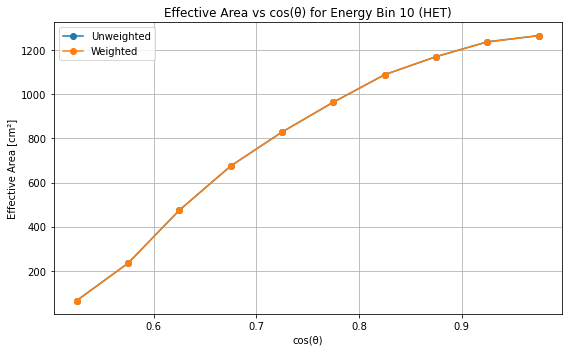

In [23]:
## Plot angular evolution for a given energy bin
energy_bin_index = 10  # Change this to the desired energy bin index
if energy_bin_index < 0 or energy_bin_index >= n_E_bins_HET:
    raise ValueError(f"Energy bin index {energy_bin_index} is out of range. Must be between 0 and {n_E_bins_HET-1}.")   
# Extract the effective area for the specified energy bin
eff_area_for_energy_bin = df_results[df_results['E_bin_HET'] == energy_bin_index]['effArea']
eff_area_for_energy_bin_w = df_results[df_results['E_bin_HET'] == energy_bin_index]['effArea_w']    
# Extract the corresponding theta bins and their centers
theta_bins_for_energy = theta_bins_center
# Create the plot

plt.figure(figsize=(8, 5))
plt.plot(theta_bins_for_energy, eff_area_for_energy_bin.values, label='Unweighted', marker='o')
plt.plot(theta_bins_for_energy, eff_area_for_energy_bin_w.values, label='Weighted', marker='o')
plt.xscale('linear')
plt.xlabel("cos(θ)")
plt.ylabel("Effective Area [cm²]")
plt.title(f"Effective Area vs cos(θ) for Energy Bin {energy_bin_index} (HET)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig(figPath + f"effArea_vs_cosTheta_energyBin{energy_bin_index}_HET_exp{exponent:.1f}.png")
plt.show()

## Explore simple efficiency over all theta

In [24]:
# Compute the unweighted inefficiency (total - accepted) for each energy bin, summed over all theta bins
efficiency_per_energy = (
    df_results.groupby('E_bin_HET')
    .apply(lambda x: (x['accepted'].sum() /x['total'].sum()))
)

grouped = df_results.groupby('E_bin_HET')


/tmp/ipykernel_3584857/2086670750.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x['accepted'].sum() /x['total'].sum()))


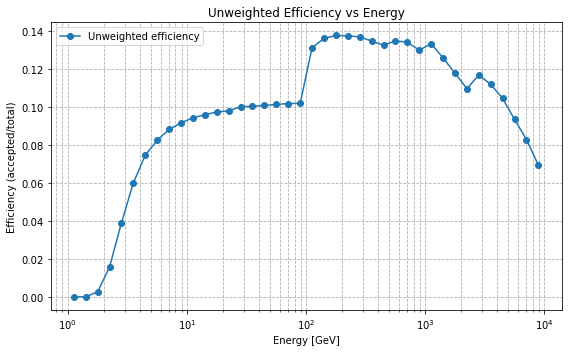

In [25]:

# Plot inefficiency vs energy bin center
plt.figure(figsize=(8, 5))
plt.plot(E_bins_center_HET, efficiency_per_energy.values, marker='o', label='Unweighted efficiency')
plt.xscale('log')
plt.yscale('linear')
plt.xlabel("Energy [GeV]")
plt.ylabel("Efficiency (accepted/total)")
plt.title("Unweighted Efficiency vs Energy")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
efficiency_per_energy *= eff_area_geom


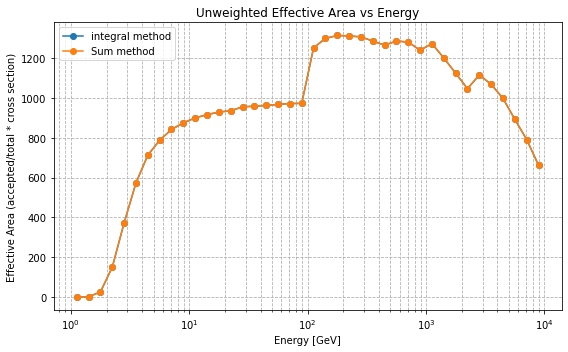

In [27]:

# Plot inefficiency vs energy bin center
plt.figure(figsize=(8, 5))
plt.plot(E_bins_center_HET, efficiency_per_energy.values, marker='o', label='integral method')
plt.plot(df_results_energy['E_bin_HET'], df_results_energy['effArea'], label='Sum method', marker='o')
plt.xscale('log')
plt.yscale('linear')
plt.xlabel("Energy [GeV]")
plt.ylabel("Effective Area (accepted/total * cross section)")
plt.title("Unweighted Effective Area vs Energy")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.show()

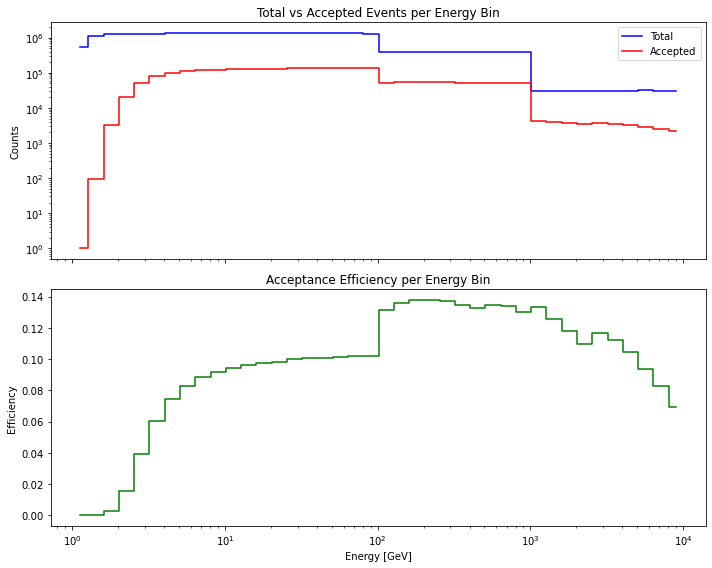

In [28]:
# Compute histogram counts for both datasets in energy bins
total_counts, _ = np.histogram(df['E_true'], bins=E_bins_edge_HET)
accepted_counts, _ = np.histogram(dfHET['E_true'], bins=E_bins_edge_HET)

# Compute bin centers for plotting
E_bin_centers = 0.5 * (E_bins_edge_HET[:-1] + E_bins_edge_HET[1:])

# Avoid division by zero in ratio calculation
efficiency = np.divide(
    accepted_counts, total_counts,
    out=np.zeros_like(accepted_counts, dtype=float),
    where=total_counts != 0
)

# Plot histograms and ratio
fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Top plot: total and accepted counts
axs[0].step(E_bin_centers, total_counts, where='mid', label='Total', color='blue')
axs[0].step(E_bin_centers, accepted_counts, where='mid', label='Accepted', color='red')
axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].set_ylabel("Counts")
axs[0].legend()
axs[0].set_title("Total vs Accepted Events per Energy Bin")

# Bottom plot: efficiency
axs[1].step(E_bin_centers, efficiency, where='mid', color='green')
axs[1].set_xscale('log')
axs[1].set_ylabel("Efficiency")
axs[1].set_xlabel("Energy [GeV]")
axs[1].set_title("Acceptance Efficiency per Energy Bin")

plt.tight_layout()
plt.show()